# Phase 2 — Bayesian inference and model selection

New in Jan: Bayesian families with explicit physical priors (circle, ellipse, hyperbola,
equant circle, epicycles), `bayes.mcmc` (emcee), `bayes.hmc` (NumPyro NUTS),
`bayes.nested` (dynesty: evidences and model probabilities) and `gp.sky`. Rudolf adds
probabilistic predictive scores, credible-interval coverage, model-selection metrics, corner
and posterior-predictive plots; the bench adds caching, timeouts and calibration across
seeds. Sweeps: `bench/eight_arcminutes.yaml`, `bench/calibration_mars.yaml`,
`bench/fourier_overfit.yaml`, `bench/epicycle_truth.yaml`.

In [1]:
import os, warnings
os.chdir('/home/dylan/Projects/jan-and-tycho')
os.environ.setdefault("MPLBACKEND", "Agg")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160)

from IPython.display import Video
def results(name):
    p = Path("runs/sweeps") / name / "results.parquet"
    if not p.exists():
        print(f"(missing) run: jt bench sweep bench/{name}.yaml --workers 14 && jt bench report runs/sweeps/{name}")
        return None
    return pd.read_parquet(p)
def show(name, fig, width=760):
    p = Path("runs/sweeps") / name / "figures" / fig
    display(Image(filename=str(p), width=width)) if p.exists() else print(f"(missing figure {p})")
def cell_fig(name, scenario, label, fig, seed=0, width=760):
    """A per-run figure (or MP4) from a sweep cell."""
    p = Path("runs/sweeps") / name / "cells" / scenario / "base" / str(seed) / "rudolf" / label / "figures" / fig
    if not p.exists():
        print(f"(missing figure {p})")
    elif p.suffix == ".mp4":
        display(Video(str(p), embed=True, width=width))
    else:
        display(Image(filename=str(p), width=width))

## Evidence with nested sampling

Orbit posteriors are needle-like inside wide physical priors, so `bayes.nested` finds each
family's MAP and runs dynesty in a box of ±8 Laplace σ around it. With priors uniform in the
physical coordinates, ln Z = ln Z_box + ln V_box + ln π exactly when the posterior lies in the
box (edge-crowding triggers a larger box). Families whose best fit trails the leader by more
than 200 nats get a Laplace evidence instead (they are excluded either way). A unit test checks
that box evidences agree with Laplace evidences to < 1.5 nats on a near-Gaussian posterior.

**Modelling choice.** The equant circle obeys Kepler's third law like the conics. With a free
period it pays a 10–20 nat Occam penalty however well it fits, which would turn the
"eight arcminutes" question into a question about the period prior.

## Acceptance 1 — `epicycle_truth`: nested sampling prefers epicycles

In [2]:
df = results("epicycle_truth")
if df is not None:
    d = df[df.strategy == "bayes.nested"]
    display(d[["seed", "selected_family", "p_true_family", "p_epicycles", "p_conic-elliptic", "p_equant-circle"]])
    print("prefers epicycles in", int((d.selected_family == "epicycles").sum()), "of", len(d), "seeds")

,seed,selected_family,p_true_family,p_epicycles,p_conic-elliptic,p_equant-circle
0,0,epicycles,1.0,1.0,0.0,0.0
4,1,epicycles,1.0,1.0,0.0,0.0
8,2,epicycles,1.0,1.0,0.0,0.0
12,3,epicycles,1.0,1.0,0.0,0.0
16,4,epicycles,1.0,1.0,0.0,0.0


prefers epicycles in 5 of 5 seeds


## Acceptance 2 — the eight-arcminutes sweep (ellipse vs equant circle)

In [3]:
df = results("eight_arcminutes")
if df is not None:
    d = df[(df.strategy == "bayes.nested") & (df.status == "ok")]
    tab = d.pivot_table(index="noise.0.sigma_arcsec", columns="schedule.cadence_days", values="p_true_family", aggfunc="median")
    display(Markdown("Median posterior probability of the ellipse (true family), noise σ (″) × cadence (days):"))
    display(tab.round(3))
    n_obs = df[df.strategy == "classical.lsq"].groupby("schedule.cadence_days")["n_holdout"].median()

Median posterior probability of the ellipse (true family), noise σ (″) × cadence (days):

schedule.cadence_days,10,30,90
noise.0.sigma_arcsec,,,
10,1.000,1.000,1.000
60,1.000,1.000,1.000
240,1.000,1.000,1.000
480,1.000,1.000,1.000
1200,1.000,1.000,0.997
2400,1.000,0.998,0.942
3600,0.998,0.974,0.845


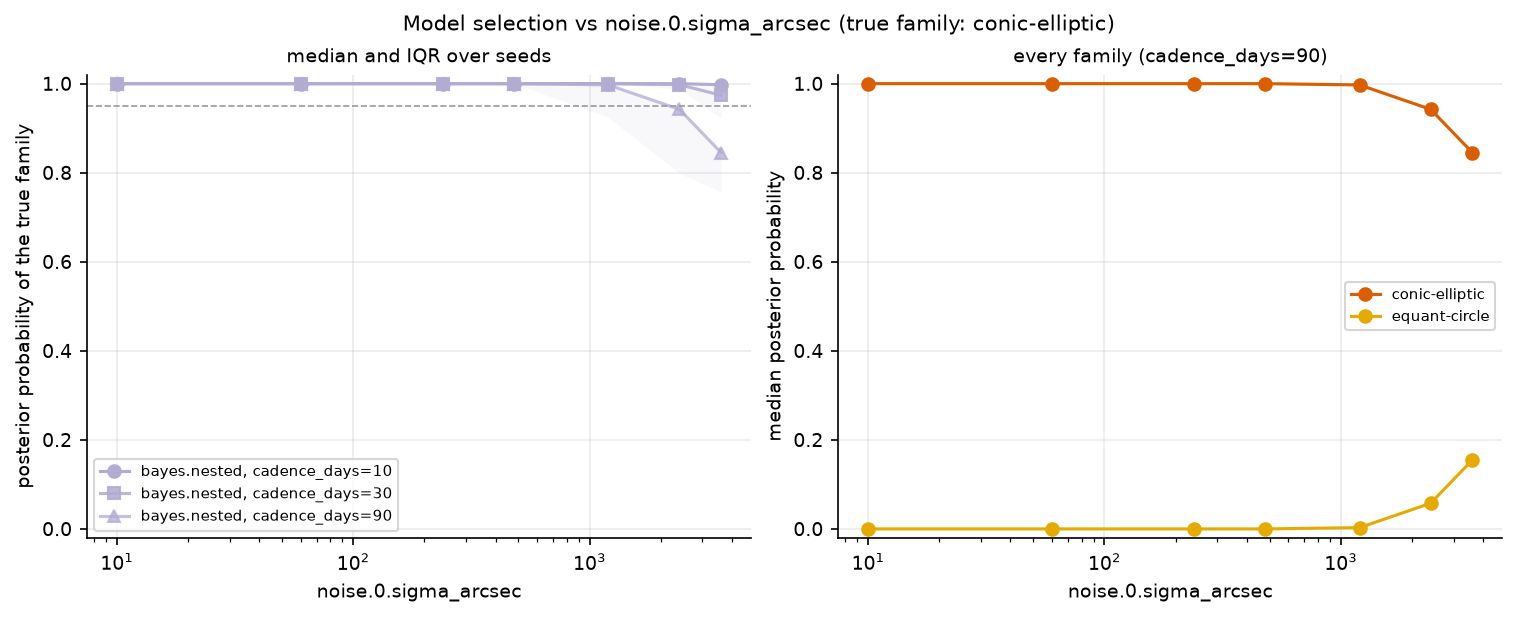

In [4]:
show("eight_arcminutes", "model_selection_vs_noise__noise_0_sigma_arcsec__schedule_cadence_days.png")

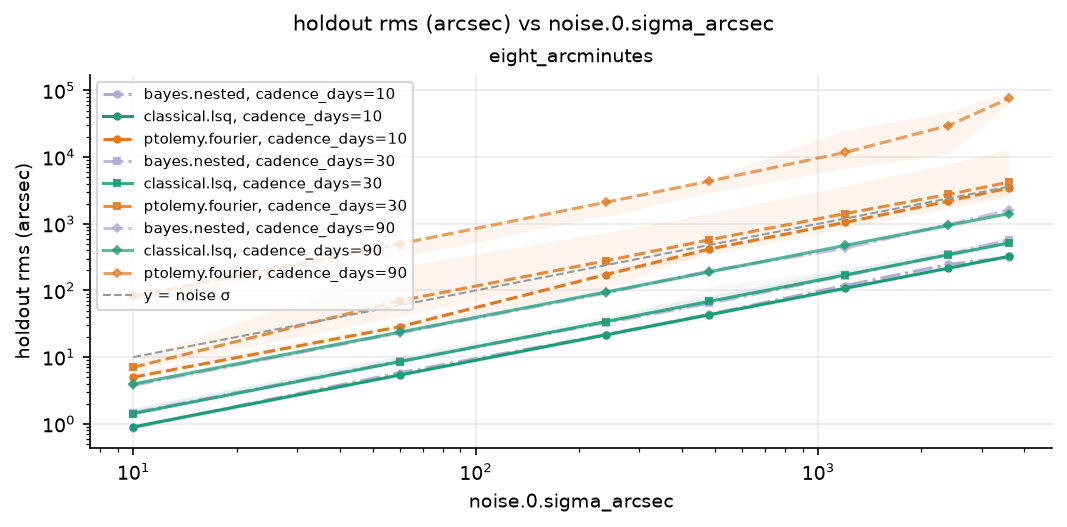

In [5]:
show("eight_arcminutes", "error_vs_tycho_param__noise_0_sigma_arcsec__schedule_cadence_days__holdout_rms_arcsec.png")

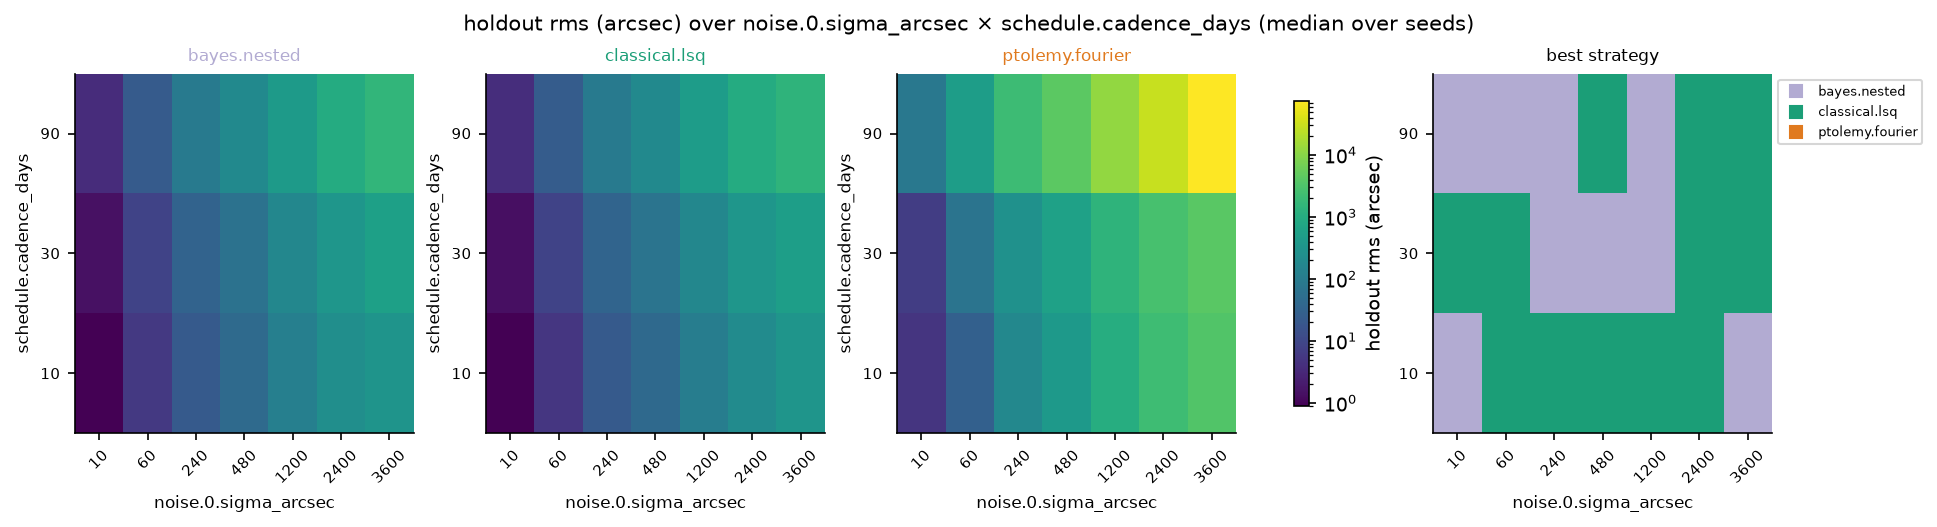

In [6]:
show("eight_arcminutes", "heatmap_2d__noise_0_sigma_arcsec__schedule_cadence_days.png", 900)

## Acceptance 3 — calibration of `bayes.hmc` on `mars_like` (50 seeds)

In [7]:
df = results("calibration_mars")
if df is not None:
    rows = []
    for lab, g in df[df.status == "ok"].groupby("label"):
        for el in ["q", "e", "i", "Omega", "omega", "t_p"]:
            c95, c68 = f"in95_{el}", f"in68_{el}"
            if c95 in g:
                v95 = g[c95].dropna().astype(float); v68 = g[c68].dropna().astype(float)
                rows.append({"strategy": lab, "element": el, "n": len(v95), "cover68": v68.mean(), "cover95": v95.mean()})
    cov = pd.DataFrame(rows)
    display(cov.pivot(index="element", columns="strategy", values="cover95").round(3))
    h = cov[cov.strategy == "bayes.hmc"]
    print(f"bayes.hmc 95% coverage per element: {h.cover95.min():.2f}–{h.cover95.max():.2f} (criterion 0.90–0.99)")

strategy,bayes.hmc,bayes.mcmc,classical.lsq
element,,,
Omega,0.92,0.96,0.96
e,1.00,1.00,1.00
i,0.92,0.96,0.94
omega,0.94,0.94,0.94
q,1.00,1.00,1.00
t_p,0.98,0.98,0.98


bayes.hmc 95% coverage per element: 0.92–1.00 (criterion 0.90–0.99)


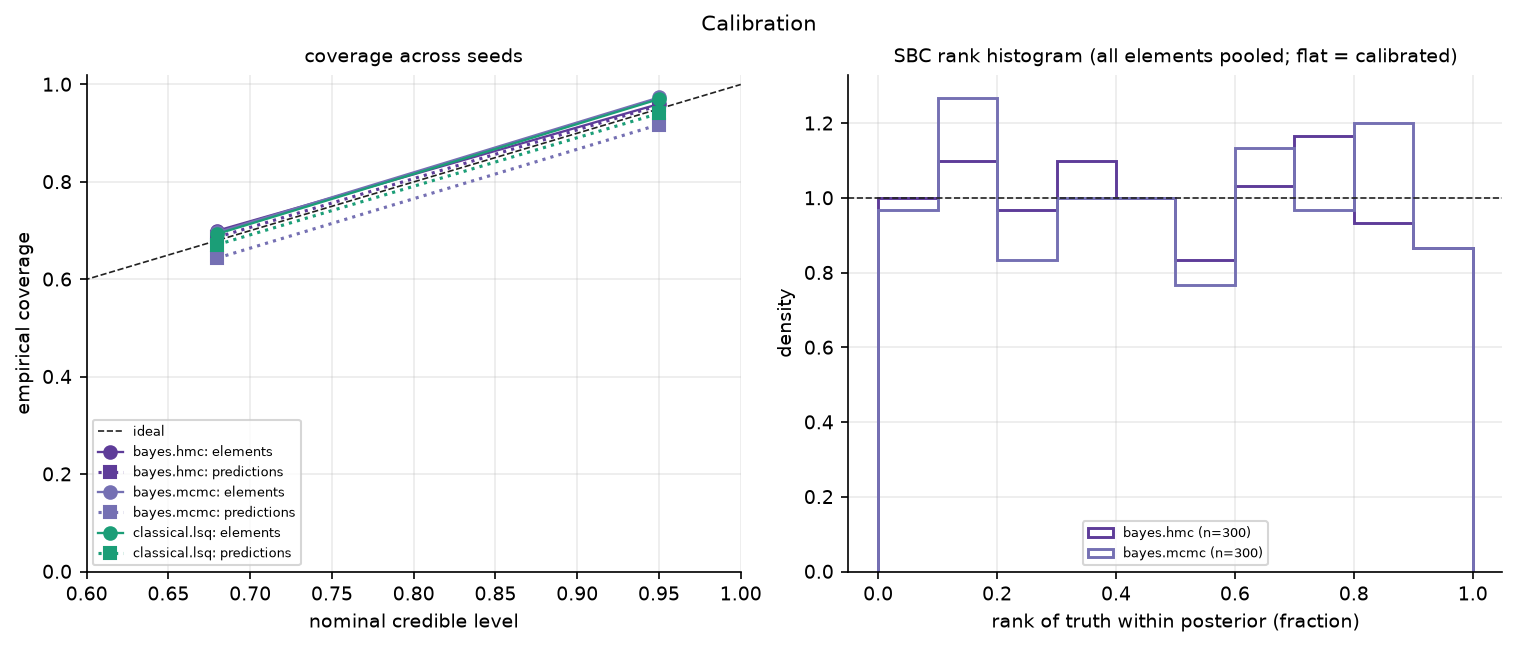

In [8]:
show("calibration_mars", "calibration.png", 900)

## Acceptance 4 — overfitting with epicycle order

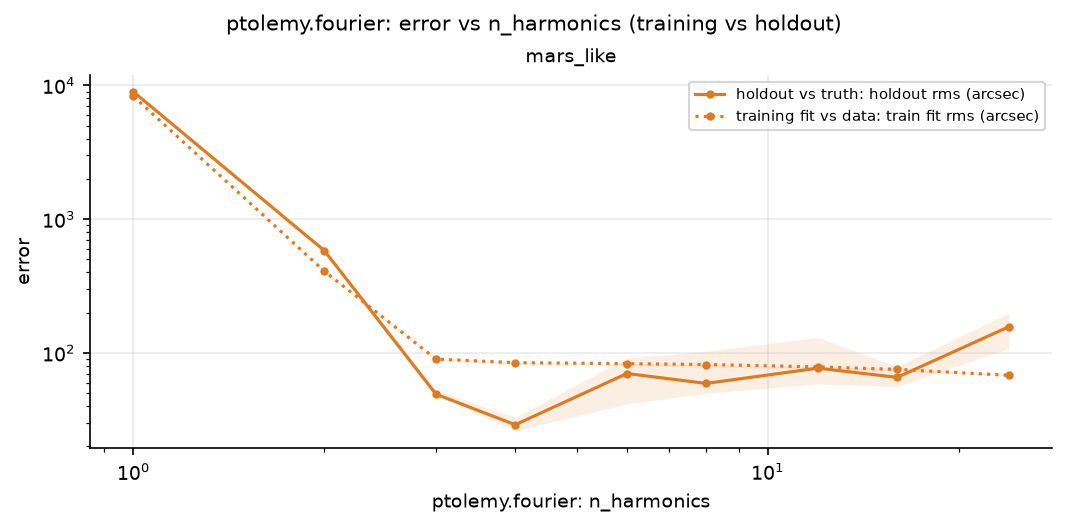

In [9]:
show("fourier_overfit", "error_vs_jan_param__ptolemy_fourier__n_harmonics.png")

In [10]:
df = results("fourier_overfit")
if df is not None:
    display(df.groupby("jan.n_harmonics")[["train_fit_rms_arcsec", "holdout_rms_arcsec"]].median().round(1))

,train_fit_rms_arcsec,holdout_rms_arcsec
jan.n_harmonics,,
1,8296.2,8963.8
2,408.2,581.7
3,89.9,49.1
4,84.5,29.0
6,83.1,70.1
8,81.8,59.1
12,78.6,76.8
16,75.3,65.6
24,67.9,156.6
